图形已保存至: F:\TUB\greenlandProject\ERA5LAND\beifen\Picture\Greenland_Station_Classification.png


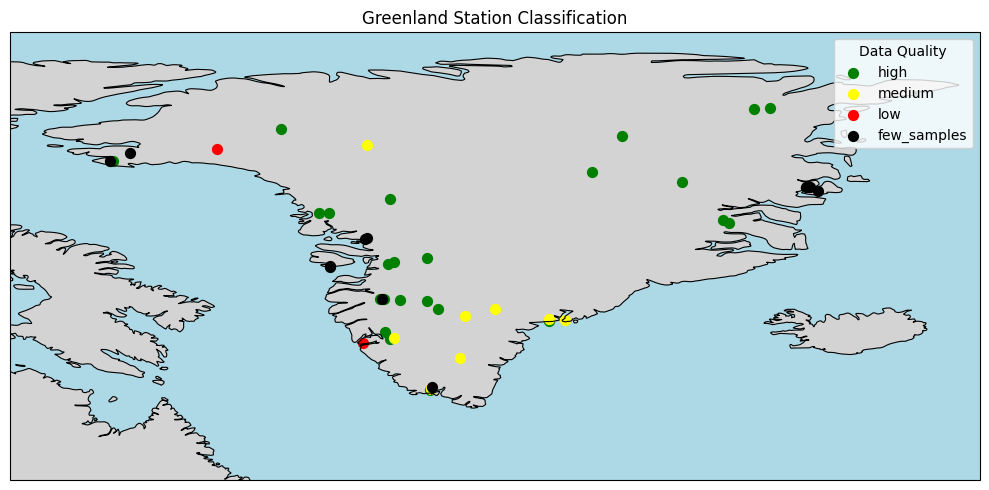

In [9]:
import matplotlib.pyplot as plt

# 站点数据
stations = {
    "CEN": (77.18, -61.12),
    "CP1": (69.87, -47.04),
    "DY2": (66.48, -46.29),
    "EGP": (75.63, -35.97),
    "FRE": (74.39, -20.83),
    "HUM": (78.53, -56.85),
    "JAR": (69.49, -49.67),
    "KAN_B": (67.13, -50.18),
    "KAN_L": (67.10, -49.93),
    "KAN_M": (67.07, -48.85),
    "KAN_T": (67.15, -50.04),
    "KAN_U": (67.00, -47.04),
    "KPC_L": (79.91, -24.09),
    "KPC_U": (79.83, -25.16),
    "LYN_L": (69.32, -53.54),
    "LYN_T": (69.30, -53.59),
    "MIT": (65.69, -37.83),
    "NAE": (75.00, -29.98),
    "NAU": (73.84, -49.54),
    "NEM": (77.44, -51.08),
    "NSE": (66.48, -42.49),
    "NUK_K": (64.16, -51.36),
    "NUK_L": (64.48, -49.56),
    "NUK_N": (64.95, -49.88),
    "NUK_U": (64.51, -49.29),
    "QAS_A": (61.24, -46.73),
    "QAS_L": (61.03, -46.85),
    "QAS_M": (61.11, -46.81),
    "QAS_U": (61.17, -46.82),
    "RED_L": (76.93, -66.96),
    "SCO_L": (72.22, -26.82),
    "SCO_U": (72.39, -27.21),
    "SDL": (66.00, -44.50),
    "SDM": (63.15, -44.82),
    "SWC": (69.59, -49.28),
    "TAS_A": (65.77, -38.89),
    "TAS_L": (65.64, -38.90),
    "TAS_U": (65.70, -38.87),
    "THU_L": (76.40, -68.27),
    "THU_L2": (76.39, -68.27),
    "THU_U": (76.39, -68.11),
    "TUN": (78.02, -33.96),
    "UPE_L": (72.89, -54.30),
    "UPE_U": (72.88, -53.62),
    "WEG_B": (71.14, -51.22),
    "WEG_L": (71.20, -51.10),
    "ZAC_A": (74.65, -21.65),
    "ZAC_L": (74.62, -21.37),
    "ZAC_U": (74.64, -21.46),
}

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 假设 stations 是包含经纬度信息的字典
# stations = {'CP1': (lat, lon), 'DY2': (lat, lon), ...}

# 手动定义数据质量分类
quality_dict = {
    # R² > 0.7 (高预测性能)
    'high': [
        'CP1', 'DY2', 'EGP', 'HUM', 'JAR', 'KAN_B', 'KAN_L', 'KAN_M', 'KAN_U',
        'KPC_L', 'KPC_U', 'NAE', 'NAU', 'NUK_L', 'NUK_N', 'QAS_L', 'SCO_L',
        'SCO_U', 'SWC', 'TAS_L', 'TAS_U', 'THU_L', 'THU_U', 'TUN', 'UPE_L', 'UPE_U'
    ],
    
    # R² ≈ 0.4–0.7 (中等预测性能)
    'medium': [
        'MIT', 'NEM', 'NSE', 'NUK_U', 'QAS_M', 'QAS_U', 'SDL', 'SDM', 'TAS_A'
    ],
    
    # R² < 0.4 (低预测性能)
    'low': [
        'CEN', 'NUK_K'
    ],
    
    # 样本数过少（<20）
    'few_samples': [
        'FRE', 'KAN_T', 'LYN_L', 'LYN_T', 'QAS_A', 'RED_L', 'THU_L2', 
        'WEG_B', 'WEG_L', 'ZAC_A', 'ZAC_L', 'ZAC_U'
    ]
}

# 颜色映射
color_map = {
    'high': 'green',
    'medium': 'yellow',
    'low': 'red',
    'few_samples': 'black'
}

# 创建图形和地理坐标轴
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 添加地理特征
ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='lightgray')
ax.add_feature(cfeature.OCEAN.with_scale('50m'), facecolor='lightblue')
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=0.8)
ax.add_feature(cfeature.BORDERS.with_scale('50m'), linestyle=':')

# 设置地图范围（格陵兰附近）
ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())

# 绘制站点
for quality, station_list in quality_dict.items():
    latitudes = [stations[s][0] for s in station_list if s in stations]
    longitudes = [stations[s][1] for s in station_list if s in stations]
    ax.scatter(longitudes, latitudes, 
               label=quality, 
               color=color_map[quality], 
               s=50, 
               edgecolors='face',
               transform=ccrs.PlateCarree())  # 确保使用正确的坐标转换

# 添加图例和标签
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Greenland Station Classification")
plt.legend(title="Data Quality")
plt.grid(True)
plt.tight_layout()

# 保存图形
output_path = r"F:\TUB\greenlandProject\ERA5LAND\beifen\Picture\Greenland_Station_Classification.png"
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"图形已保存至: {output_path}")

# 显示图形（可选）
plt.show()


In [3]:
# ----------------- 划分训练/验证集 --- 基础模型/堆叠 --- 评估 --- 保存3个PKL并打印绝对路径 ------------------
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import joblib
from scipy.stats import pearsonr

# 读取和筛选数据（注意 Windows 路径使用原始字符串 r"" 以避免转义问题）
file_path = r"C:\greenland\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "asn", "year", "month"
]  # 删掉了 "sde" 的版本
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
data = data[data["year"] >= 1995]

if data.empty:
    raise RuntimeError("After filtering, no data remains for years >= 1995.")

X = data[input_features].astype(float)
y = data[target_column].astype(float)

# 拆分训练/测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 定义基础模型（屏蔽训练时无关日志）
models = {
    'RF': RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(
        n_estimators=500, n_jobs=-1, random_state=42,
        tree_method="hist", verbosity=0
    ),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(
        n_estimators=1000, n_jobs=-1, random_state=42,
        verbose=-1  # 关键：屏蔽 LightGBM 的 [Info] 日志
    ),
    'CatBoost': catboost.CatBoostRegressor(
        iterations=1000, random_seed=42, verbose=0
    )
}

# 5折构造元特征（out-of-fold）
kf = KFold(n_splits=5, shuffle=True, random_state=42)
model_names = list(models.keys())
meta_features = np.zeros((X_train.shape[0], len(model_names)))

for j, name in enumerate(model_names):
    model = models[name]
    oof_pred = np.zeros(X_train.shape[0])
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        oof_pred[val_idx] = model.predict(X_val)
    meta_features[:, j] = oof_pred

# 元模型训练
meta_model = Ridge()
meta_model.fit(meta_features, y_train)

# 全量训练基础模型（用于最终预测）
trained_base_models = []
for name in model_names:
    m = models[name]
    m.fit(X_train, y_train)
    trained_base_models.append(m)

# 测试集堆叠预测
test_meta_features = np.column_stack([m.predict(X_test) for m in trained_base_models])
final_preds = meta_model.predict(test_meta_features)

# 模型评估（仅打印一条汇总，不打印训练库的详细日志）
r2 = r2_score(y_test, final_preds)
r, _ = pearsonr(y_test, final_preds)
mse = mean_squared_error(y_test, final_preds)
rmse = np.sqrt(mse)
print(f"R²: {r2:.6f}, R: {r:.6f}, RMSE: {rmse:.6f}, MSE: {mse:.6f}")

# ===== 保存模型：1) 整体堆叠 2) 仅基础模型 3) 仅元模型 =====
save_dir = os.path.abspath(os.getcwd())
prefix = "NoSdestacking_model"

stacking_model = {
    'trained_base_models': trained_base_models,
    'meta_model': meta_model,
    'base_model_names': model_names,  # 保留顺序，便于将来复现
    'input_features': input_features  # 方便推理时校验
}

path_all  = os.path.join(save_dir, f"{prefix}.pkl")
path_base = os.path.join(save_dir, f"{prefix}_base_models.pkl")
path_meta = os.path.join(save_dir, f"{prefix}_meta_model.pkl")

joblib.dump(stacking_model, path_all)
joblib.dump(trained_base_models, path_base)
joblib.dump(meta_model, path_meta)

print("Saved (all-in-one):", os.path.abspath(path_all))
print("Saved (base models):", os.path.abspath(path_base))
print("Saved (meta model):", os.path.abspath(path_meta))



R²: 0.883752, R: 0.940111, RMSE: 0.061686, MSE: 0.003805
Saved (all-in-one): C:\Users\11823\era5land\NoSdestacking_model.pkl
Saved (base models): C:\Users\11823\era5land\NoSdestacking_model_base_models.pkl
Saved (meta model): C:\Users\11823\era5land\NoSdestacking_model_meta_model.pkl


   conda remove -y xgboost
   conda clean --all -y
   conda install -c conda-forge xgboost -y
   

conda create -n xgboost_env python=3.8
conda activate xgboost_env
conda install -c conda-forge xgboost jupyter notebook pandas scikit-learn

R²: 0.884667, R: 0.940781, RMSE: 0.063130, MSE: 0.003985


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.



--- Model Saving Results ---
Saved (all-in-one): C:\Users\11823\era5land\202209202402\NoSdestacking_model_Pre202209.pkl
Saved (base models): C:\Users\11823\era5land\202209202402\NoSdestacking_model_Pre202209_base_models.pkl
Saved (meta model): C:\Users\11823\era5land\202209202402\NoSdestacking_model_Pre202209_meta_model.pkl


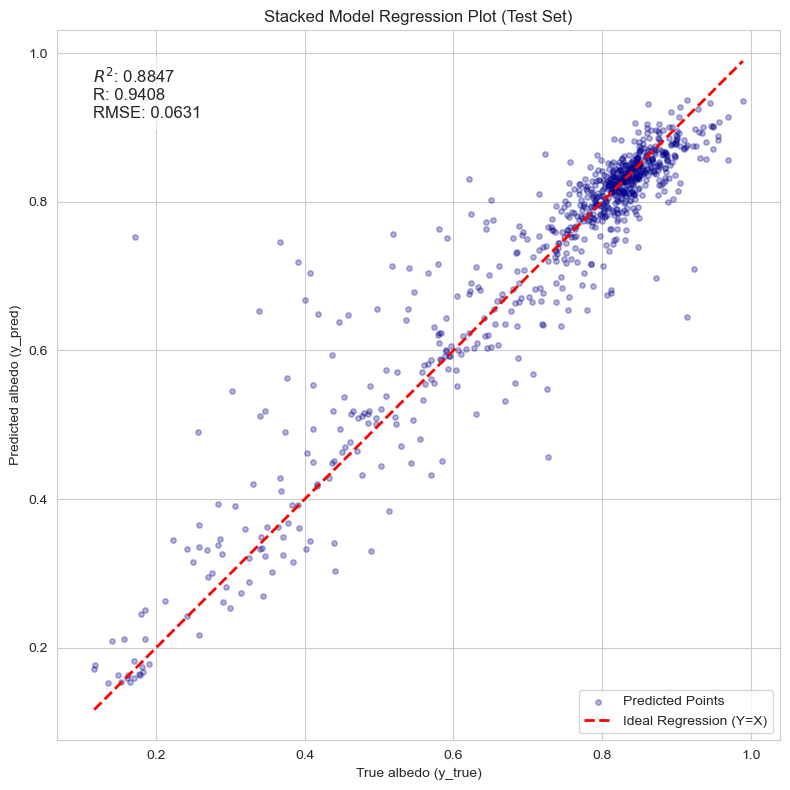

Saved Regression Plot: C:\Users\11823\era5land\202209202402\NoSdestacking_model_Pre202209_regression_plot.png


In [11]:
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import joblib
from scipy.stats import pearsonr
# 导入绘图库
import matplotlib.pyplot as plt
import seaborn as sns 

# 定义新的保存目录
NEW_SAVE_DIR = r"C:\Users\11823\era5land\202209202402"
os.makedirs(NEW_SAVE_DIR, exist_ok=True) # 确保目录存在

# 读取和筛选数据（注意 Windows 路径使用原始字符串 r"" 以避免转义问题）
file_path = r"C:\greenland\merged_allfeature.csv"  
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "asn", "year", "sde", "month"
]   
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
data = data[data["year"] >= 1995]

# =================================================================
# 关键修改：剔除 2022年9月 到 2024年2月 的数据
# 1. year=2022 且 month >= 9
filter1 = (data["year"] == 2022) & (data["month"] >= 9)
# 2. year=2023 (所有月份)
filter2 = (data["year"] == 2023)
# 3. year=2024 且 month <= 2
filter3 = (data["year"] == 2024) & (data["month"] <= 2)

# 组合过滤条件：保留不在这个时间范围内的数据
# 使用 ~((filter1) | (filter2) | (filter3))
exclude_time_period = filter1 | filter2 | filter3
data = data[~exclude_time_period]
# =================================================================


if data.empty:
    raise RuntimeError("After filtering, no data remains for years >= 1995 or after excluding the 2022/09-2024/02 period.")

X = data[input_features].astype(float)
y = data[target_column].astype(float)

# 拆分训练/测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 定义基础模型（屏蔽训练时无关日志）
models = {
    'RF': RandomForestRegressor(n_estimators=500, n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(
        n_estimators=500, n_jobs=-1, random_state=42,
        tree_method="hist", verbosity=0
    ),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(
        n_estimators=1000, n_jobs=-1, random_state=42,
        verbose=-1   # 关键：屏蔽 LightGBM 的 [Info] 日志
    ),
    'CatBoost': catboost.CatBoostRegressor(
        iterations=1000, random_seed=42, verbose=0
    )
}

# 5折构造元特征（out-of-fold）
kf = KFold(n_splits=5, shuffle=True, random_state=42)
model_names = list(models.keys())
meta_features = np.zeros((X_train.shape[0], len(model_names)))

for j, name in enumerate(model_names):
    model = models[name]
    oof_pred = np.zeros(X_train.shape[0])
    for tr_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
        model.fit(X_tr, y_tr)
        oof_pred[val_idx] = model.predict(X_val)
    meta_features[:, j] = oof_pred

# 元模型训练
meta_model = Ridge()
meta_model.fit(meta_features, y_train)

# 全量训练基础模型（用于最终预测）
trained_base_models = []
for name in model_names:
    m = models[name]
    m.fit(X_train, y_train)
    trained_base_models.append(m)

# 测试集堆叠预测
test_meta_features = np.column_stack([m.predict(X_test) for m in trained_base_models])
final_preds = meta_model.predict(test_meta_features)

# 模型评估（仅打印一条汇总，不打印训练库的详细日志）
r2 = r2_score(y_test, final_preds)
r, _ = pearsonr(y_test, final_preds)
mse = mean_squared_error(y_test, final_preds)
rmse = np.sqrt(mse)
print(f"R²: {r2:.6f}, R: {r:.6f}, RMSE: {rmse:.6f}, MSE: {mse:.6f}")

# ===== 保存模型：1) 整体堆叠 2) 仅基础模型 3) 仅元模型 =====
prefix = "NoSdestacking_model_Pre202209" 

stacking_model = {
    'trained_base_models': trained_base_models,
    'meta_model': meta_model,
    'base_model_names': model_names,   # 保留顺序，便于将来复现
    'input_features': input_features   # 方便推理时校验
}

# 构造完整的保存路径
path_all  = os.path.join(NEW_SAVE_DIR, f"{prefix}.pkl")
path_base = os.path.join(NEW_SAVE_DIR, f"{prefix}_base_models.pkl")
path_meta = os.path.join(NEW_SAVE_DIR, f"{prefix}_meta_model.pkl")

# 保存模型文件
joblib.dump(stacking_model, path_all)
joblib.dump(trained_base_models, path_base)
joblib.dump(meta_model, path_meta)

print("\n--- Model Saving Results ---")
print("Saved (all-in-one):", os.path.abspath(path_all))
print("Saved (base models):", os.path.abspath(path_base))
print("Saved (meta model):", os.path.abspath(path_meta))

# =================================================================
# 新增代码：绘制测试集回归点图
# =================================================================
try:
    # 设置绘图风格
    sns.set_style("whitegrid")
    
    # 将 Series 转换为 numpy 数组，确保维度一致
    y_true = y_test.values
    y_pred = final_preds
    
    # 确定绘图范围
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    
    # 创建图表
    plt.figure(figsize=(8, 8))
    
    # 绘制散点图 (Predicted vs. True)
    plt.scatter(y_true, y_pred, alpha=0.3, s=15, label='Predicted Points', color='darkblue')
    
    # 绘制 1:1 理想回归线
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Regression (Y=X)')
    
    # 添加评估指标文本
    text_info = (f"$R^2$: {r2:.4f}\n"
                 f"R: {r:.4f}\n"
                 f"RMSE: {rmse:.4f}")
    
    plt.text(0.05, 0.95, text_info, transform=plt.gca().transAxes, 
             fontsize=12, verticalalignment='top', 
             bbox=dict(boxstyle="round,pad=0.5", fc="white", alpha=0.6))
    
    # 设置标签和标题
    plt.xlabel(f'True {target_column} (y_true)')
    plt.ylabel(f'Predicted {target_column} (y_pred)')
    plt.title('Stacked Model Regression Plot (Test Set)')
    plt.legend(loc='lower right')
    plt.axis('equal') # 确保x轴和y轴比例一致
    plt.xlim(min_val - 0.05, max_val + 0.05)
    plt.ylim(min_val - 0.05, max_val + 0.05)
    plt.tight_layout()
    
    # 保存图表
    plot_path = os.path.join(NEW_SAVE_DIR, f"{prefix}_regression_plot.png")
    plt.savefig(plot_path, dpi=300)
    
    # 显示图表
    plt.show()
    
    print("Saved Regression Plot:", os.path.abspath(plot_path))

except Exception as e:
    print(f"\nError occurred during plotting: {e}")
    print("Please ensure you have matplotlib and seaborn installed (`pip install matplotlib seaborn`).")

# =================================================================

In [12]:
import joblib
import pandas as pd
import numpy as np
import os
import warnings
import re

# 屏蔽一切警告
warnings.filterwarnings("ignore")

# 加载整体堆叠模型
stacking_model_path = r"C:\Users\11823\era5land\202209202402\NoSdestacking_model_Pre202209.pkl"
try:
    stacking_model = joblib.load(stacking_model_path)
    trained_base_models = stacking_model['trained_base_models']
    meta_model = stacking_model['meta_model']
    base_model_names = stacking_model['base_model_names']
    # input_features = stacking_model['input_features'] # 保持使用自定义的 input_features
except FileNotFoundError:
    print(f"❌ 错误：模型文件未找到于 {stacking_model_path}")
    exit()
except KeyError as e:
    print(f"❌ 错误：模型文件中缺少必要的键：{e}")
    exit()

# 输入特征
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "asn", "year", "sde", "month"
]
target_column = "albedo"

# 输入输出路径
input_folder = r"C:\greenland\ProcessedCSV"
output_folder = r"C:\Users\11823\era5land\202209202402"

# 创建输出文件夹（如不存在）
os.makedirs(output_folder, exist_ok=True)

# 设置要处理的年份范围（可修改）
start_year = 1950
end_year = 2024

# 分批处理大小
chunk_size = 1000

# 遍历所有文件
for filename in os.listdir(input_folder):
    # 提取年份（假设文件名中前4位是年份，如199507Greenland_allfeature.csv）
    match = re.match(r"(\d{4})\d{2}.*allfeature\.csv", filename)
    if match:
        year = int(match.group(1))
        
        # 构造预期的输出文件名
        file_prefix = filename.replace("allfeature.csv", "")
        output_file = os.path.join(output_folder, f"{file_prefix}prediction.csv")

        # --- 新增：检查预测结果文件是否已存在，如果存在则跳过 ---
        if os.path.exists(output_file):
            print(f"⏩ 文件 {filename} 的预测结果已存在于 {output_file}，跳过处理。")
            continue
        # --------------------------------------------------------

        if start_year <= year <= end_year:
            filepath = os.path.join(input_folder, filename)
            
            print(f"⏳ 开始处理文件: {filename}")
            
            try:
                # 优化：只读取需要的列，减少内存占用（如果 albedo 不在输入文件中，则不需要读取 target_column）
                # 原始文件中可能包含 target_column，但我们只用 input_features
                data = pd.read_csv(filepath, usecols=input_features) 
                # 重新读取完整的行，以便保留所有原始列和索引
                data_full = pd.read_csv(filepath) 
                data_input = data_full[input_features]


                all_results = []

                # 使用 iloc/loc 进行切片时，需要确保索引的对应性，这里使用完整的 data_full 和 data_input
                for start in range(0, len(data_input), chunk_size):
                    chunk_input = data_input.iloc[start:start + chunk_size]
                    chunk_full = data_full.iloc[start:start + chunk_size]
                    
                    # 找出非NaN的行索引
                    clean_indices = chunk_input.dropna().index
                    
                    # 确保索引非空
                    if clean_indices.empty:
                        continue

                    # 提取干净的数据块
                    chunk_clean_input = chunk_input.loc[clean_indices]
                    
                    # 使用干净的输入进行预测
                    base_preds = [model.predict(chunk_clean_input) for model in trained_base_models]
                    
                    # 检查 base_preds 是否为空，理论上不会如果 clean_indices 不为空
                    if not base_preds:
                        continue
                        
                    stacked_input = np.column_stack(base_preds)
                    final_preds = meta_model.predict(stacked_input)

                    # 在完整的行数据上，根据干净的索引进行切片
                    data_clean = chunk_full.loc[clean_indices].copy()
                    
                    # 将预测结果赋给 albedo 列
                    data_clean[target_column] = final_preds
                    all_results.append(data_clean)

                if all_results:
                    final_data = pd.concat(all_results, axis=0)
                    
                    # 检查 output_file 是否已被检查过（此处冗余，但作为双重保险）
                    if not os.path.exists(output_file):
                        final_data.to_csv(output_file, index=False)
                        print(f"✅ 文件 {output_file} 输出成功，共 {len(final_data)} 行")
                    else:
                        print(f"⚠️ 文件 {filename} 的预测结果已在检查期间生成，不再重复输出。")
                else:
                    print(f"⚠️ 文件 {filename} 没有有效数据，跳过")

            except Exception as e:
                print(f"❌ 处理文件 {filename} 出错：{e}")
                continue

⏩ 文件 195004allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195004prediction.csv，跳过处理。
⏩ 文件 195005allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195005prediction.csv，跳过处理。
⏩ 文件 195006allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195006prediction.csv，跳过处理。
⏩ 文件 195007allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195007prediction.csv，跳过处理。
⏩ 文件 195008allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195008prediction.csv，跳过处理。
⏩ 文件 195009allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195009prediction.csv，跳过处理。
⏩ 文件 195104allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195104prediction.csv，跳过处理。
⏩ 文件 195105allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195105prediction.csv，跳过处理。
⏩ 文件 195106allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195106prediction.csv，跳过处理。
⏩ 文件 195107allfeature.csv 的预测结果已存在于 C:\Users\11823\era5land\202209202402\195107prediction.csv，跳过处理。


In [ ]:
#删掉了 "sde",的版本 用于验证sde的影响，后证明没有影响
# 文件 C:\greenland\NosdePrediction\202208prediction.csv 输出成功，共 82482 行
#✅ 文件 C:\greenland\NosdePrediction\202209prediction.csv 输出成功，共 82482 行
#✅ 文件 C:\greenland\NosdePrediction\202304prediction.csv 输出成功，共 82482 行

In [ ]:
#裁剪-------------greenland区域--------------
import os
import pandas as pd

# 1. 读取边界经纬度点文件路径
boundary_file = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\GreenlandBoundryBu.csv"
input_dir = r"F:\TUB\greenlandProject\ERA5LAND\MonthlyFeatures\1995prediction"
output_dir = input_dir  # 保存到原目录，文件名加_clip

print("开始读取边界文件...")
boundary_df = pd.read_csv(boundary_file)
print(f"边界文件加载完成，读取到 {len(boundary_df)} 条经纬度点。")

# 确认列名
assert 'latitude' in boundary_df.columns and 'longitude' in boundary_df.columns, "边界文件缺少latitude或longitude列！"

# 用集合存储边界点，方便快速查找
boundary_coords = set(zip(boundary_df['latitude'], boundary_df['longitude']))
print(f"边界点转换为集合，便于快速匹配。")

# 遍历所有csv文件
files = [f for f in os.listdir(input_dir) if f.endswith('.csv') and not f.endswith('_clip.csv')]
print(f"待处理文件共计 {len(files)} 个。")

for filename in files:
    # 检查输出文件是否已存在
    new_filename = filename.replace('.csv', '_clip.csv')
    new_filepath = os.path.join(output_dir, new_filename)
    
    if os.path.exists(new_filepath):
        print(f"\n跳过文件: {filename}，裁剪后的文件已存在。")
        continue
    
    print(f"\n处理文件: {filename}")
    filepath = os.path.join(input_dir, filename)
    df = pd.read_csv(filepath)
    print(f"原文件行数: {len(df)}")

    # 检查列名
    if 'latitude' not in df.columns or 'longitude' not in df.columns:
        print(f"跳过文件 {filename}，缺少latitude或longitude列。")
        continue

    coords = list(zip(df['latitude'], df['longitude']))

    # 建立mask，只有边界集合中存在的点才保留
    mask = [coord in boundary_coords for coord in coords]
    clipped_df = df[mask]

    print(f"筛选后保留行数: {len(clipped_df)}")

    # 保存新文件
    clipped_df.to_csv(new_filepath, index=False)
    print(f"保存文件: {new_filename}")

print("\n所有文件处理完成。")


In [6]:
import os
import glob
import pandas as pd
import numpy as np
from datetime import datetime
from scipy import stats

folder_path = r"F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu"
pattern = os.path.join(folder_path, "*.csv")
file_list = sorted(glob.glob(pattern))

albedo_means = []
dates = []
monthly_data = {}  # 用于存储每月数据

for file in file_list:
    # 读取csv
    df = pd.read_csv(file)
    # 计算albedo均值
    mean_albedo = df['albedo'].mean()
    albedo_means.append(mean_albedo)
    
    # 从文件名提取时间，假设格式为：YYYYMMprediction_clip.csv，比如199004prediction_clip.csv
    basename = os.path.basename(file)
    date_str = basename[:6]  # 前6位 YYYYMM
    date_obj = datetime.strptime(date_str, "%Y%m")
    dates.append(date_obj)
    
    # 存储每月数据
    month_key = date_obj.strftime("%Y-%m")
    monthly_data[month_key] = mean_albedo

# 转换为DataFrame便于分析
df_albedo = pd.DataFrame({
    'date': dates,
    'albedo_mean': albedo_means
})
df_albedo['year'] = df_albedo['date'].dt.year
df_albedo['month'] = df_albedo['date'].dt.month

# 保存均值数据到同一路径下的mean.csv
output_path = os.path.join(folder_path, "mean.csv")
df_albedo.to_csv(output_path, index=False)
print(f"均值数据已保存到: {output_path}")

# 只输出最大值、最小值和均值
print("\n===== 统计分析结果 =====")
overall_mean = np.mean(albedo_means)
min_value = np.min(albedo_means)
max_value = np.max(albedo_means)
min_date = dates[np.argmin(albedo_means)].strftime('%Y-%m')
max_date = dates[np.argmax(albedo_means)].strftime('%Y-%m')

print(f"总体均值: {overall_mean:.4f}")
print(f"最小值: {min_value:.4f} (出现在 {min_date})")
print(f"最大值: {max_value:.4f} (出现在 {max_date})")

# 趋势分析
x = np.arange(len(albedo_means))
slope, intercept, r_value, p_value, std_err = stats.linregress(x, albedo_means)

print(f"\n===== 趋势分析 =====")
print(f"趋势斜率: {slope:.6f}")
print(f"R平方值: {r_value**2:.4f}")
print(f"P值: {p_value:.4f}")

if p_value < 0.05:
    if slope > 0:
        trend_description = "显著上升趋势"
    else:
        trend_description = "显著下降趋势"
else:
    trend_description = "无显著趋势"

print(f"趋势判断: {trend_description}")

# 季节性分析
seasonal_means = df_albedo.groupby('month')['albedo_mean'].mean()
print(f"\n===== 季节性分析 =====")
print(f"春季均值 (3-5月): {seasonal_means[3:6].mean():.4f}")
print(f"夏季均值 (6-8月): {seasonal_means[6:9].mean():.4f}")
print(f"秋季均值 (9-11月): {seasonal_means[9:12].mean():.4f}")
if len(seasonal_means) >= 12:
    winter_mean = pd.concat([seasonal_means[12:], seasonal_means[1:3]]).mean()
    print(f"冬季均值 (12,1-2月): {winter_mean:.4f}")

# 年度变化分析（如果跨越多年）
if len(df_albedo['year'].unique()) > 1:
    yearly_means = df_albedo.groupby('year')['albedo_mean'].mean()
    print(f"\n===== 年度变化 =====")
    for year, mean_val in yearly_means.items():
        print(f"{year}年均值: {mean_val:.4f}")

均值数据已保存到: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\1995bu\mean.csv

===== 统计分析结果 =====
总体均值: 0.7565
最小值: 0.6728 (出现在 2012-07)
最大值: 0.8410 (出现在 2019-04)

===== 趋势分析 =====
趋势斜率: 0.000009
R平方值: 0.0008
P值: 0.5429
趋势判断: 无显著趋势

===== 季节性分析 =====
春季均值 (3-5月): 0.7236
夏季均值 (6-8月): nan
秋季均值 (9-11月): nan

===== 年度变化 =====
1950年均值: 0.7509
1951年均值: 0.7564
1952年均值: 0.7545
1953年均值: 0.7562
1954年均值: 0.7531
1955年均值: 0.7584
1956年均值: 0.7594
1957年均值: 0.7460
1958年均值: 0.7572
1959年均值: 0.7572
1960年均值: 0.7488
1961年均值: 0.7545
1962年均值: 0.7574
1963年均值: 0.7613
1964年均值: 0.7620
1965年均值: 0.7575
1966年均值: 0.7550
1967年均值: 0.7572
1968年均值: 0.7551
1969年均值: 0.7542
1970年均值: 0.7599
1971年均值: 0.7477
1972年均值: 0.7608
1973年均值: 0.7586
1974年均值: 0.7561
1975年均值: 0.7610
1976年均值: 0.7581
1977年均值: 0.7576
1978年均值: 0.7542
1979年均值: 0.7548
1980年均值: 0.7500
1981年均值: 0.7549
1982年均值: 0.7515
1983年均值: 0.7603
1984年均值: 0.7556
1985年均值: 0.7518
1986年均值: 0.7550
1987年均值: 0.7509
1988年均值: 0.7552
1989年均值: 0.7518
1990年均值: 0.7450
1991年均值

In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import shap
import matplotlib.pyplot as plt
import joblib
import os
from datetime import datetime

# ========== 1. 读取数据 ==========
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]

X = data[input_features].astype(float)
y = data[target_column]

# 检查缺失特征
missing_features = set(input_features) - set(data.columns)
if missing_features:
    raise ValueError(f"Missing features in data: {missing_features}")

# 拆分训练 / 测试集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ========== 2. 定义基础模型 ==========
models = {
    'RF': RandomForestRegressor(n_jobs=-1, random_state=42),
    'XGB': xgb.XGBRegressor(n_jobs=-1, random_state=42),
    'GBDT': GradientBoostingRegressor(random_state=42),
    'LGBM': lgb.LGBMRegressor(n_jobs=-1, random_state=42),
    'CatBoost': catboost.CatBoostRegressor(verbose=0, random_seed=42)
}

# ========== 3. 构造元特征 (K折) ==========
kf = KFold(n_splits=5, shuffle=True, random_state=42)
meta_features = np.zeros((X_train.shape[0], len(models)))
model_statistics = {}

for idx, (name, model) in enumerate(models.items()):
    meta_feature = np.zeros(X_train.shape[0])

    for train_idx, val_idx in kf.split(X_train):
        X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model.fit(X_t, y_t)
        preds = model.predict(X_val)
        meta_feature[val_idx] = preds

    meta_features[:, idx] = meta_feature

    # CV指标
    r2 = r2_score(y_train, meta_feature)
    r, _ = pearsonr(y_train, meta_feature)
    mse = mean_squared_error(y_train, meta_feature)
    rmse = np.sqrt(mse)
    bias = np.mean(meta_feature - y_train)
    model_statistics[name] = {"R2": r2, "R": r, "RMSE": rmse, "MSE": mse, "Bias": bias}

# ========== 4. 训练元模型 ==========
meta_model = Ridge()
meta_model.fit(meta_features, y_train)

# ========== 5. 训练最终基础模型 ==========
trained_base_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_base_models[name] = model

# ========== 6. 测试集预测 ==========
test_meta_features = np.column_stack([
    trained_base_models[name].predict(X_test) for name in models
])
final_preds = meta_model.predict(test_meta_features)

# ========== 7. SHAP分析 ==========
shap_model = trained_base_models['RF']  # 用RF解释
try:
    explainer = shap.TreeExplainer(shap_model)
    shap_values = explainer.shap_values(X_test)

    plt.figure()
    shap.summary_plot(shap_values, X_test, show=False)
    plt.title("SHAP Summary (RF)")
    plt.tight_layout()
    plt.savefig("shap_summary_917.png")
    plt.close()

    plt.figure()
    shap.plots.bar(explainer(X_test), max_display=15, show=False)
    plt.title("Top 15 Features by SHAP Value")
    plt.tight_layout()
    plt.savefig("shap_bar_917.png")
    plt.close()
except Exception as e:
    print(f"⚠️ SHAP Error: {str(e)}")

# ========== 8. 输出性能 ==========
r2 = r2_score(y_test, final_preds)
r, _ = pearsonr(y_test, final_preds)
mse = mean_squared_error(y_test, final_preds)
rmse = np.sqrt(mse)
bias = np.mean(final_preds - y_test)

print("\n========== Final Stacking Model Test Evaluation ==========")
print(f"R²: {r2:.6f}")
print(f"Pearson R: {r:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MSE: {mse:.6f}")
print(f"Bias: {bias:.6f}")

print("\n========== Base Model Cross-Validation Metrics ==========")
for name, stats in model_statistics.items():
    print(f"\n{name.upper()}:")
    for metric, value in stats.items():
        print(f"{metric}: {value:.6f}")

print("\n✅ 实际使用的特征:", list(X_train.columns))

# ========== 9. 保存模型 ==========
save_dir = "saved_models_917"
os.makedirs(save_dir, exist_ok=True)

# 保存基础模型
for name, model in trained_base_models.items():
    joblib.dump(model, os.path.join(save_dir, f"{name}_917.pkl"))

# 保存元模型
joblib.dump(meta_model, os.path.join(save_dir, "meta_model_917.pkl"))

print(f"\n✅ 模型已保存到 {save_dir}")


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000281 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2629
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 15
[LightGBM] [Info] Start training from score 0.727292
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000149 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2645
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 15
[LightGBM] [Info] Start training from score 0.726925
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000169 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2623
[LightGBM] [Info] Number of data points in the train set: 

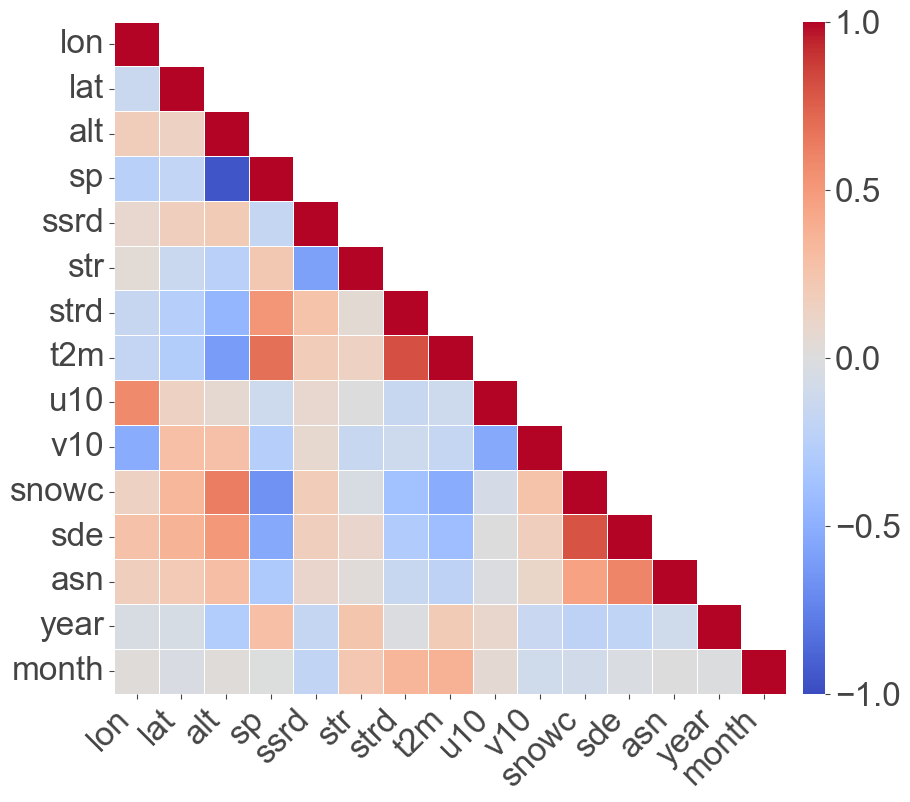

In [4]:
# -*- coding: utf-8 -*-
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ===== 路径 =====
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)

# ===== 特征列（简写 altitude）=====
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
num_df = df[input_features].astype(float)
corr = num_df.corr(method='spearman')

# ===== 简写列名映射 =====
rename_dict = {
    'longitude': 'lon',
    'latitude': 'lat',
    'altitude_last_valid': 'alt',
    'sp': 'sp',
    'ssrd': 'ssrd',
    'str': 'str',
    'strd': 'strd',
    't2m': 't2m',
    'u10': 'u10',
    'v10': 'v10',
    'snowc': 'snowc',
    'sde': 'sde',
    'asn': 'asn',
    'year': 'year',
    'month': 'month'
}

corr.rename(index=rename_dict, columns=rename_dict, inplace=True)

# ===== 遮上三角但保留对角线 =====
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# ===== npj风格设置 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 24,
    "axes.linewidth": 0.8,
    "axes.edgecolor": "black",
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

# ===== 绘制热力图 =====
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(
    corr, mask=mask,
    cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, annot=False,
    linewidths=0.4, linecolor="white",
    cbar_kws={
        "orientation": "vertical",
        "pad": 0.02,
        "shrink": 1.0,
        "aspect": 30,
        "ticks": [-1, -0.5, 0, 0.5, 1],
    },
    ax=ax
)

# ===== 美化标签 =====
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

# ===== 移除标题与图例文字 =====
cbar = ax.collections[0].colorbar
cbar.set_label("")
ax.set_title("")

# ===== 紧凑布局并保存 =====
plt.tight_layout(pad=0.3)
plt.savefig(r"C:\Users\11823\era5land\Fig_TriangularCorrelation_npJ_cleanFinal.png",
            dpi=400, bbox_inches='tight')
plt.show()

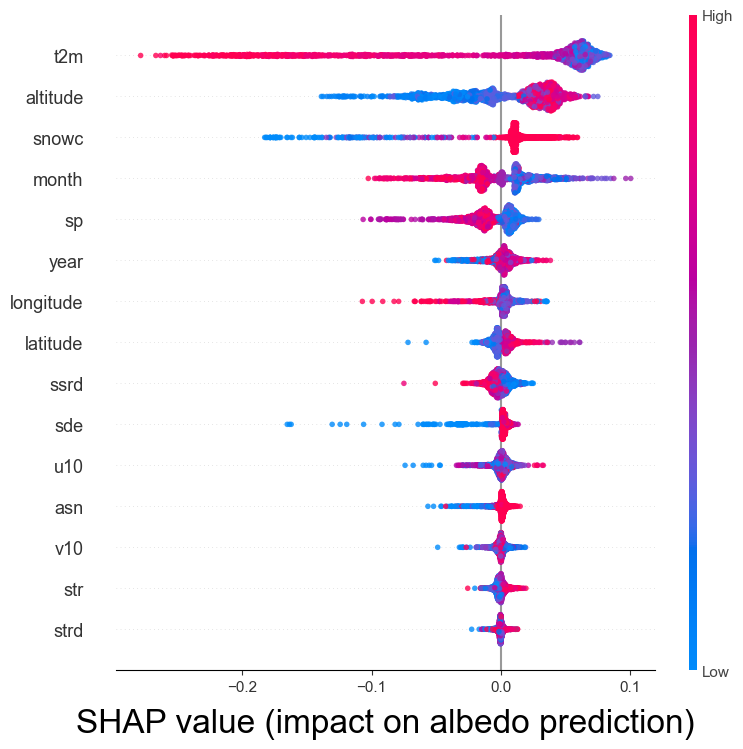

In [5]:
# -*- coding: utf-8 -*-
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import joblib
import numpy as np

# ===== 载入数据与模型（与之前一致）=====
file_path = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"
df = pd.read_csv(file_path)
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
num_df = df[input_features].astype(float)

# 重命名列以简化显示
num_df.rename(columns={'altitude_last_valid': 'altitude'}, inplace=True)

# 加载你保存的基础模型（RF）以便做 SHAP
rf_model = joblib.load(r"C:\Users\11823\era5land\saved_models_917\RF_917.pkl")

# ===== 计算 SHAP =====
explainer = shap.TreeExplainer(rf_model)
sampled = num_df.sample(2000, random_state=42)
shap_values = explainer.shap_values(sampled)

# ===== npj 风格设置 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 24,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

# ===== 颜色映射保持与热力图一致 =====
cmap = sns.color_palette("coolwarm", as_cmap=True)

# ===== 绘制 SHAP Summary Plot =====
plt.figure(figsize=(8, 7))
shap.summary_plot(
    shap_values, sampled,
    plot_type="dot",
    color=cmap,
    show=False,
    alpha=0.8
)

# ===== 删除 "Feature value" 颜色条标签 =====
cbar = plt.gcf().axes[-1]  # 获取colorbar
cbar.set_ylabel("")  # 删除 "Feature value" 文字

# ===== 去掉标题与额外文字，调整布局 =====
plt.title("")
plt.xlabel("SHAP value (impact on albedo prediction)", fontsize=24, labelpad=10)
plt.ylabel("")

# ===== 设置x轴刻度为 -0.2, -0.1, 0, 0.1 =====
plt.xticks([-0.2, -0.1, 0, 0.1])

# ===== 调整边框：删除y轴线，保留其他 =====
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)  # 删除y轴线
ax.spines["bottom"].set_visible(True)
ax.tick_params(left=False)  # 去掉y轴刻度线

plt.tight_layout(pad=0.3)

# ===== 保存图像 =====
plt.savefig(r"C:\Users\11823\era5land\Fig_SHAP_npJstyle.png",
            dpi=400, bbox_inches='tight', transparent=True)
plt.show()

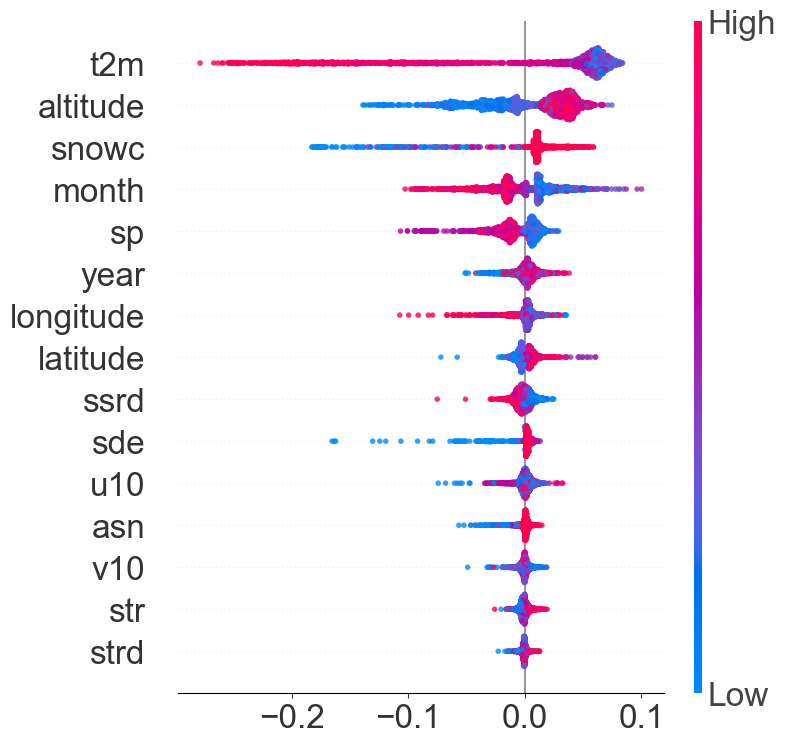

In [12]:
# -*- coding: utf-8 -*-
import shap
import matplotlib.pyplot as plt
import seaborn as sns

# ===== npj 风格设置 =====
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 30,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": "#444444",
    "ytick.color": "#444444",
})

# ===== 绘制 SHAP Summary Plot =====
plt.figure(figsize=(10, 9))
shap.summary_plot(
    shap_values,
    sampled.rename(columns={"altitude_last_valid": "altitude"}),
    plot_type="dot",
    color=sns.color_palette("coolwarm", as_cmap=True),
    show=False,
    alpha=0.8
)

# ===== 删除 "Feature value" 颜色条标签 =====
cbar = plt.gcf().axes[-1]  # 获取colorbar
cbar.set_ylabel("")  # 删除 "Feature value" 文字
# 设置colorbar刻度字号
cbar.tick_params(labelsize=24)

# ===== 删除标题和轴标签 =====
plt.title("")
plt.xlabel("")
plt.ylabel("")

# ===== 设置x轴刻度为 -0.2, -0.1, 0, 0.1 =====
plt.xticks([-0.2, -0.1, 0, 0.1])

# ===== 手动设置所有文字大小（关键！）=====
ax = plt.gca()
ax.tick_params(axis='both', labelsize=24)  # x轴和y轴刻度标签
ax.xaxis.label.set_fontsize(24)
ax.yaxis.label.set_fontsize(24)

# 设置y轴特征名称字号
for label in ax.get_yticklabels():
    label.set_fontsize(24)
    label.set_family('Arial')

# 设置x轴数值字号
for label in ax.get_xticklabels():
    label.set_fontsize(24)
    label.set_family('Arial')

# ===== 调整边框：删除y轴线，保留其他 =====
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)  # 删除y轴线
ax.spines["bottom"].set_visible(True)
ax.tick_params(left=False)  # 去掉y轴刻度线

plt.tight_layout(pad=0.3)
plt.savefig(r"C:\Users\11823\era5land\Fig_SHAP_npJ_final_clean.png",
            dpi=400, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split, KFold
import xgboost as xgb
import lightgbm as lgb
import catboost

# 读取数据
file_path = "F:/TUB/greenlandProject/ERA5LAND/merged_allfeature.csv"
original_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "sde", "asn", "year", "month"
]
target_column = "albedo"
exclude_stations = ["QAS_M", "MIT", "NUK_K"]

data = pd.read_csv(file_path)
data = data[~data["station"].isin(exclude_stations)]
y = data[target_column]

# 存储所有堆叠模型结果
stacking_results = []

# 轮询每个特征
for feature_to_remove in original_features:
    # 当前使用的特征
    current_features = [f for f in original_features if f != feature_to_remove]
    X = data[current_features].copy().astype(float)
    
    # 拆分训练测试集
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 定义模型
    models = {
        'RF': RandomForestRegressor(n_jobs=-1, random_state=42),
        'XGB': xgb.XGBRegressor(n_jobs=-1, random_state=42),
        'GBDT': GradientBoostingRegressor(random_state=42),
        'LGBM': lgb.LGBMRegressor(n_jobs=-1, random_state=42),
        'CatBoost': catboost.CatBoostRegressor(verbose=0, random_seed=42)
    }

    # 构造元特征
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    meta_features = np.zeros((X_train.shape[0], len(models)))
    
    for idx, (name, model) in enumerate(models.items()):
        meta_feature = np.zeros(X_train.shape[0])
        for train_idx, val_idx in kf.split(X_train):
            X_t, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_t, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            model.fit(X_t, y_t)
            meta_feature[val_idx] = model.predict(X_val)
        meta_features[:, idx] = meta_feature

    # 元模型训练
    meta_model = Ridge()
    meta_model.fit(meta_features, y_train)

    # 全量训练基础模型
    trained_base_models = [model.fit(X_train, y_train) for model in models.values()]

    # 测试集堆叠预测
    test_meta_features = np.column_stack([model.predict(X_test) for model in trained_base_models])
    final_preds = meta_model.predict(test_meta_features)

    # 计算指标
    r2 = r2_score(y_test, final_preds)
    r, _ = pearsonr(y_test, final_preds)
    rmse = np.sqrt(mean_squared_error(y_test, final_preds))
    bias = np.mean(final_preds - y_test)

    stacking_results.append({
        "Removed Feature": feature_to_remove,
        "R2": r2,
        "Pearson R": r,
        "RMSE": rmse,
        "Bias": bias,
        "Remaining Features": len(current_features)
    })

# 输出结果
print("\n========== Stacking Model Results (Leave-One-Feature-Out) ==========")
print(f"{'Removed Feature':<20} {'R²':>8} {'Pearson R':>10} {'RMSE':>10} {'Bias':>10} {'Features':>10}")
print("-" * 80)
for result in stacking_results:
    print(f"{result['Removed Feature']:<20} {result['R2']:>8.4f} {result['Pearson R']:>10.4f} "
          f"{result['RMSE']:>10.4f} {result['Bias']:>10.4f} {result['Remaining Features']:>10}")

# 找出影响最大的特征
worst_r2 = min(stacking_results, key=lambda x: x['R2'])
print("\n⚠️ Most harmful feature to remove:", worst_r2['Removed Feature'])
print(f"   (R² dropped to {worst_r2['R2']:.4f} when removed)")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000328 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2583
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 14
[LightGBM] [Info] Start training from score 0.727292
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000306 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2599
[LightGBM] [Info] Number of data points in the train set: 2695, number of used features: 14
[LightGBM] [Info] Start training from score 0.726925
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000258 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2577
[LightGBM] [Info] Number of data points in the train set: 

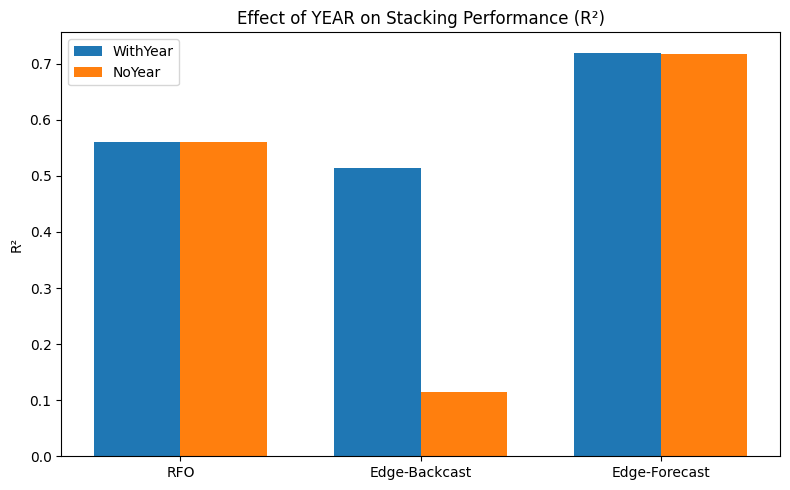

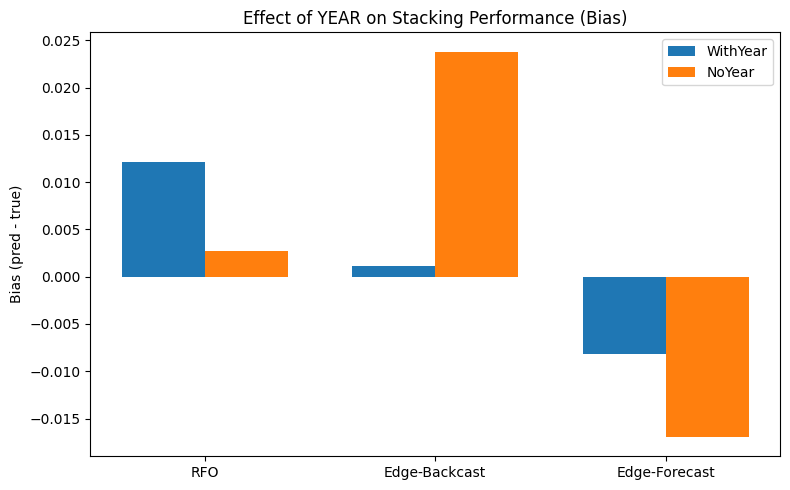

In [23]:
# -*- coding: utf-8 -*-
# Pure YEAR-effect analysis with stacking and bar charts (no prints)

import numpy as np
import pandas as pd
from collections import OrderedDict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import GroupKFold, KFold
from scipy.stats import pearsonr

import xgboost as xgb
import lightgbm as lgb
import catboost
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt


# ========== CONFIG ==========
CSV_PATH     = r"F:/TUB/greenlandProject/ERA5LAND/merged_allfeature.csv"
TRAIN_START  = 1995
TRAIN_END    = 2024
N_BLOCKS_RFO = 5
INNER_SPLITS = 5
RANDOM_STATE = 42
# ============================


# ---------- utils ----------
def safe_pearsonr(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    return float(pearsonr(y_true, y_pred)[0])

def compute_metrics(y_true, y_pred):
    return {
        "R2":   float(r2_score(y_true, y_pred)),
        "R":    safe_pearsonr(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "Bias": float(np.mean(y_pred - y_true)),
    }

def ensure_cols(df, cols, name="DataFrame"):
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise ValueError(f"{name} 缺少列: {missing}")

def years_mask(df, year_col, start_y, end_y):
    return (df[year_col] >= start_y) & (df[year_col] <= end_y)


# ---------- data ----------
def load_data(csv_path):
    df = pd.read_csv(csv_path)
    if "station" in df.columns:
        df = df[~df["station"].isin(["QAS_M", "MIT", "NUK_K"])].reset_index(drop=True)
    return df


# ---------- models ----------
def build_models(random_state=42):
    # 不在 .fit() 传 verbose，避免兼容性问题；LGBM 静音通过构造参数
    return OrderedDict([
        ("RF", RandomForestRegressor(
            n_estimators=100, max_depth=5, n_jobs=-1, random_state=random_state
        )),
        ("XGB", xgb.XGBRegressor(
            n_estimators=100, max_depth=5, n_jobs=-1, random_state=random_state
        )),
        ("GBDT", GradientBoostingRegressor(
            n_estimators=100, max_depth=5, random_state=random_state
        )),
        ("LGBM", lgb.LGBMRegressor(
            n_estimators=100, max_depth=5, n_jobs=-1, random_state=random_state,
            verbosity=-1, force_col_wise=True
        )),
        ("CatBoost", catboost.CatBoostRegressor(
            iterations=100, depth=5, verbose=0, random_seed=random_state
        )),
    ])


# ---------- stacking with inner OOF ----------
def fit_stacking_with_inner_oof(X_train, y_train, X_test, groups_train=None,
                                inner_splits=5, random_state=42):
    base_models = build_models(random_state)

    # GroupKFold by station（若组数不足，退化到 KFold）
    use_groups = groups_train is not None
    if use_groups:
        unique_groups = np.unique(groups_train)
        n_splits = min(inner_splits, len(unique_groups))
        if n_splits < 2:
            use_groups = False

    if use_groups:
        gkf = GroupKFold(n_splits=n_splits)
        split_iter_template = ("group", gkf)
    else:
        # 确保 n_splits >= 2
        n_splits = max(2, min(inner_splits, len(X_train)//2 if len(X_train) > 2 else 2))
        kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
        split_iter_template = ("kfold", kf)

    oof_meta = np.zeros((len(X_train), len(base_models)))

    for m_idx, (name, _) in enumerate(base_models.items()):
        if split_iter_template[0] == "group":
            split_iter = split_iter_template[1].split(X_train, y_train, groups=groups_train)
        else:
            split_iter = split_iter_template[1].split(X_train, y_train)

        for tr_idx, va_idx in split_iter:
            X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
            X_va       = X_train.iloc[va_idx]

            mdl = build_models(random_state)[name]
            mdl.fit(X_tr, y_tr)
            oof_meta[va_idx, m_idx] = mdl.predict(X_va)

    # meta learner
    meta = Ridge(alpha=1.0)
    meta.fit(oof_meta, y_train)

    # retrain base models on all training data
    fitted_base = OrderedDict()
    for name, mdl in build_models(random_state).items():
        mdl.fit(X_train, y_train)
        fitted_base[name] = mdl

    test_meta = np.column_stack([m.predict(X_test) for m in fitted_base.values()])
    y_pred = meta.predict(test_meta)

    coef = meta.coef_.ravel() if hasattr(meta, "coef_") else np.full(len(base_models), np.nan)
    return y_pred, coef


# ---------- time splits (train-year-only evaluation) ----------
def rfo_year_blocks(df_all, year_col='year', start=1995, end=2024, n_blocks=5):
    years = np.sort(df_all.loc[years_mask(df_all, year_col, start, end), year_col].unique())
    if len(years) < n_blocks:
        n_blocks = max(2, len(years))
    splits = np.array_split(years, n_blocks)
    blocks = []
    for i, test_years in enumerate(splits):
        if i == 0:
            continue  # 需要历史训练
        train_years = np.concatenate(splits[:i])
        blocks.append((train_years, test_years))
    return blocks

def edge_holdout_pairs():
    # 你可按需调整边缘区间
    backcast_train = (2000, 2024)
    backcast_test  = (1995, 1999)
    forecast_train = (1995, 2019)
    forecast_test  = (2020, 2024)
    return {
        "Edge-Backcast": (backcast_train, backcast_test),
        "Edge-Forecast": (forecast_train, forecast_test),
    }


# ---------- main ----------
def main():
    # 1) 读数据
    df = load_data(CSV_PATH)

    # 必要列（全部使用原始特征；只对 YEAR 做开关）
    BASE_FEATURES = [
        "longitude","latitude","altitude_last_valid","sp","ssrd","str","strd",
        "t2m","u10","v10","snowc","sde","asn","month"  # 13 物理/空间 + month = 14
    ]
    required = BASE_FEATURES + ["year","albedo"]
    ensure_cols(df, required, "training data")

    # 仅用 1995–2024 训练/评估
    mask_train = years_mask(df, "year", TRAIN_START, TRAIN_END)
    df_tr = df.loc[mask_train].reset_index(drop=True)

    # 两套特征：仅 YEAR 是否加入不同
    with_year_cols = BASE_FEATURES + ["year"]
    no_year_cols   = BASE_FEATURES

    feature_sets = OrderedDict({
        "WithYear": with_year_cols,
        "NoYear":   no_year_cols
    })

    metrics_rows = []

    for feat_name, cols in feature_sets.items():
        X_all = df_tr[cols].reset_index(drop=True)
        y_all = df_tr["albedo"].reset_index(drop=True)
        groups = df_tr["station"].values if "station" in df_tr.columns else None

        # RFO（滚动起点扩展）
        rfo_blocks = rfo_year_blocks(df_tr, year_col="year",
                                     start=TRAIN_START, end=TRAIN_END, n_blocks=N_BLOCKS_RFO)
        rfo_metrics = []
        for (train_years, test_years) in rfo_blocks:
            tr_mask = df_tr["year"].isin(train_years)
            te_mask = df_tr["year"].isin(test_years)

            X_tr, y_tr = X_all[tr_mask].reset_index(drop=True), y_all[tr_mask].reset_index(drop=True)
            X_te, y_te = X_all[te_mask].reset_index(drop=True), y_all[te_mask].reset_index(drop=True)
            grp_tr     = groups[tr_mask] if groups is not None else None

            y_pred, _ = fit_stacking_with_inner_oof(
                X_tr, y_tr, X_te, groups_train=grp_tr,
                inner_splits=INNER_SPLITS, random_state=RANDOM_STATE
            )
            rfo_metrics.append(compute_metrics(y_te, y_pred))

        if rfo_metrics:
            agg = {k: float(np.mean([m[k] for m in rfo_metrics])) for k in rfo_metrics[0].keys()}
            metrics_rows.append({"FeatureSet": feat_name, "Strategy": "RFO", **agg})

        # Edge Holdout（前/后沿）
        for tag, ((tr_s, tr_e), (te_s, te_e)) in edge_holdout_pairs().items():
            tr_mask = years_mask(df_tr, "year", tr_s, tr_e)
            te_mask = years_mask(df_tr, "year", te_s, te_e)
            if tr_mask.sum() == 0 or te_mask.sum() == 0:
                continue

            X_tr, y_tr = X_all[tr_mask].reset_index(drop=True), y_all[tr_mask].reset_index(drop=True)
            X_te, y_te = X_all[te_mask].reset_index(drop=True), y_all[te_mask].reset_index(drop=True)
            grp_tr     = groups[tr_mask] if groups is not None else None

            y_pred, _ = fit_stacking_with_inner_oof(
                X_tr, y_tr, X_te, groups_train=grp_tr,
                inner_splits=INNER_SPLITS, random_state=RANDOM_STATE
            )
            met = compute_metrics(y_te, y_pred)
            metrics_rows.append({"FeatureSet": feat_name, "Strategy": tag, **met})

    metrics_df = pd.DataFrame(metrics_rows)
    metrics_df = metrics_df[["FeatureSet","Strategy","R2","R","RMSE","Bias"]]

    # ---- 条形图：R² & Bias 对比（仅 YEAR 开关差异）----
    order = ["RFO","Edge-Backcast","Edge-Forecast"]
    r2_pivot   = metrics_df.pivot(index="Strategy", columns="FeatureSet", values="R2").reindex(order)
    bias_pivot = metrics_df.pivot(index="Strategy", columns="FeatureSet", values="Bias").reindex(order)

    # R²
    fig1 = plt.figure(figsize=(8, 5))
    x = np.arange(len(order))
    width = 0.36
    plt.bar(x - width/2, r2_pivot["WithYear"].values, width, label="WithYear")
    plt.bar(x + width/2, r2_pivot["NoYear"].values,  width, label="NoYear")
    plt.xticks(x, order, rotation=0)
    plt.ylabel("R²")
    plt.title("Effect of YEAR on Stacking Performance (R²)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Bias
    fig2 = plt.figure(figsize=(8, 5))
    x = np.arange(len(order))
    width = 0.36
    plt.bar(x - width/2, bias_pivot["WithYear"].values, width, label="WithYear")
    plt.bar(x + width/2, bias_pivot["NoYear"].values,  width, label="NoYear")
    plt.xticks(x, order, rotation=0)
    plt.ylabel("Bias (pred - true)")
    plt.title("Effect of YEAR on Stacking Performance (Bias)")
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 返回表格对象（不打印）
    return metrics_df


if __name__ == "__main__":
    _ = main()


总共有 46 个有效站点用于留站点验证
站点列表: ['CEN', 'CP1', 'DY2', 'EGP', 'FRE', 'HUM', 'JAR', 'KAN_B', 'KAN_L', 'KAN_M', 'KAN_T', 'KAN_U', 'KPC_L', 'KPC_U', 'LYN_L', 'LYN_T', 'NAE', 'NAU', 'NEM', 'NSE', 'NUK_L', 'NUK_N', 'NUK_U', 'QAS_A', 'QAS_L', 'QAS_U', 'RED_L', 'SCO_L', 'SCO_U', 'SDL', 'SDM', 'SWC', 'TAS_A', 'TAS_L', 'TAS_U', 'THU_L2', 'THU_L', 'THU_U', 'TUN', 'UPE_L', 'UPE_U', 'WEG_B', 'WEG_L', 'ZAC_A', 'ZAC_L', 'ZAC_U']

正在处理测试站点: CEN
  结果: R²=-0.6050, R=0.0526, RMSE=0.0497, MAE=0.0337

正在处理测试站点: CP1
  结果: R²=0.0721, R=0.5623, RMSE=0.0607, MAE=0.0462

正在处理测试站点: DY2
  结果: R²=0.4055, R=0.7156, RMSE=0.0338, MAE=0.0260

正在处理测试站点: EGP
  结果: R²=-1.7827, R=0.0828, RMSE=0.0545, MAE=0.0448

正在处理测试站点: FRE
  结果: R²=0.5624, R=0.9138, RMSE=0.1986, MAE=0.1812

正在处理测试站点: HUM
  结果: R²=-0.3877, R=0.2967, RMSE=0.0319, MAE=0.0247

正在处理测试站点: JAR
  结果: R²=0.6236, R=0.8051, RMSE=0.0972, MAE=0.0806

正在处理测试站点: KAN_B
  结果: R²=-0.5098, R=0.7606, RMSE=0.2551, MAE=0.2276

正在处理测试站点: KAN_L
  结果: R²=0.0283, R=0.7838, RMSE=0.093

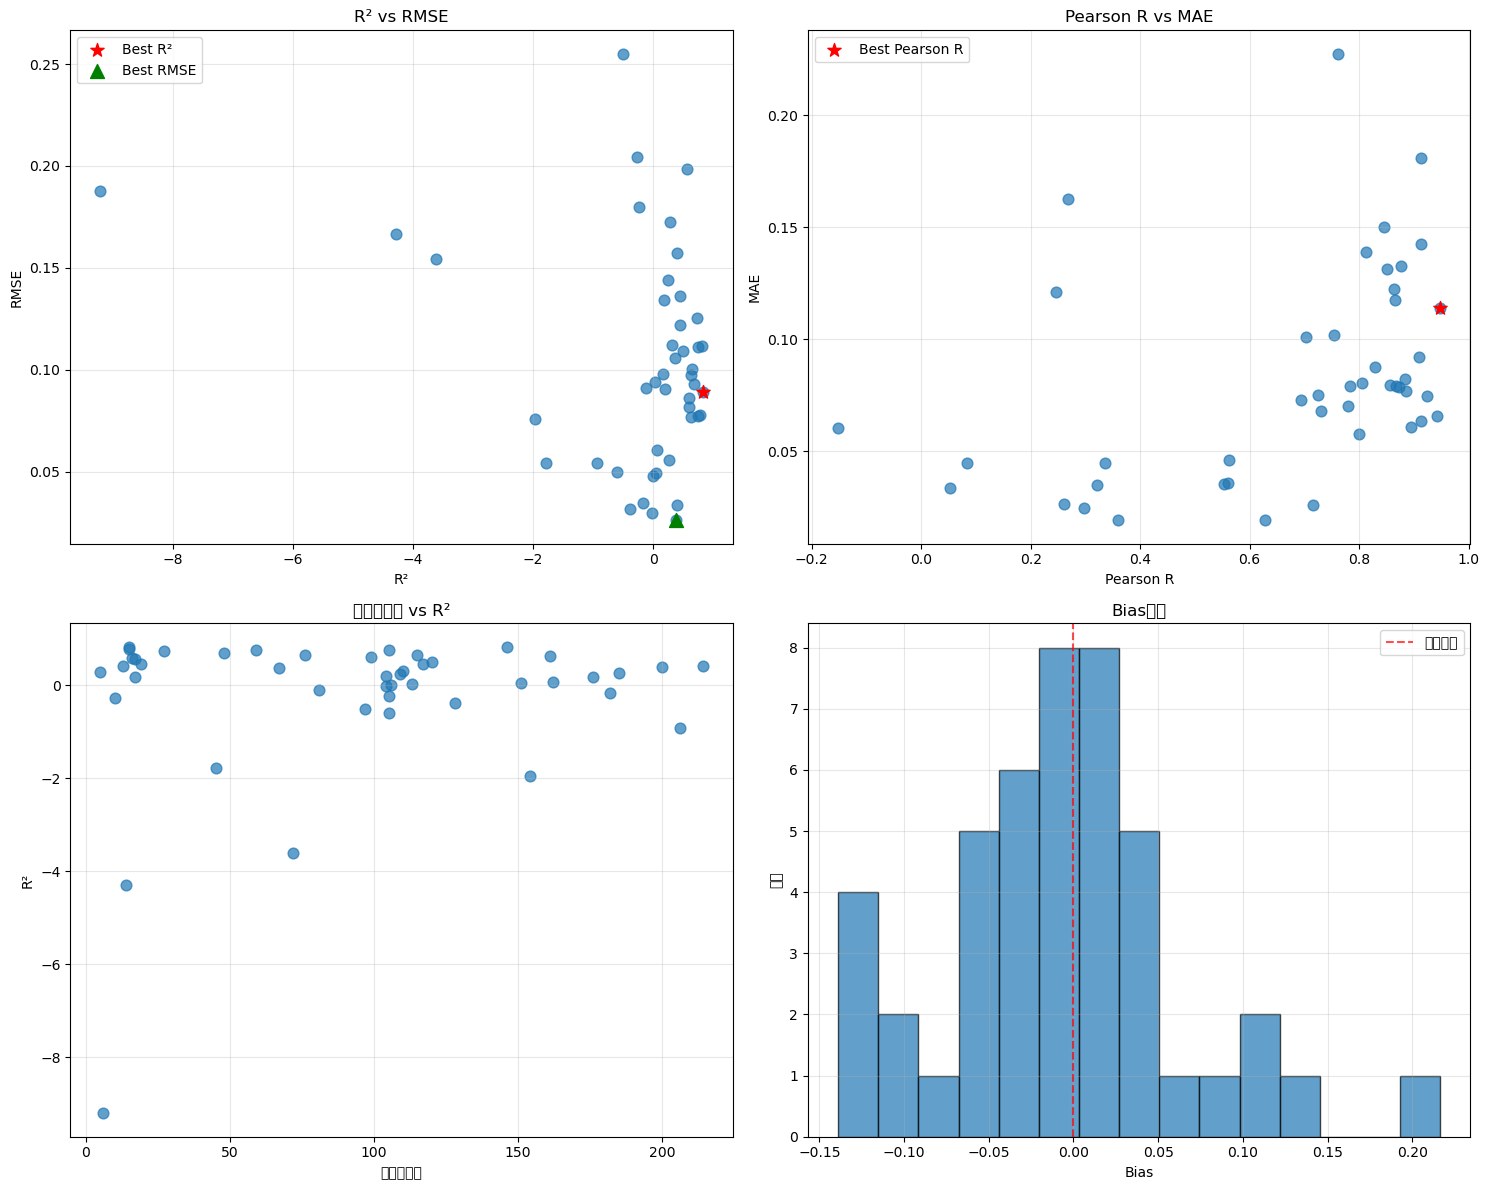


结果已保存到: leave_one_station_out_results.csv

========== 统计摘要 ==========
R² 范围: -9.2082 - 0.8246 (均值: -0.2305)
RMSE 范围: 0.0261 - 0.2551 (均值: 0.1032)
Pearson R 范围: -0.1520 - 0.9484 (均值: 0.6733)
MAE 范围: 0.0192 - 0.2276 (均值: 0.0832)
Bias 范围: -0.1389 - 0.2166 (均值: -0.0073)


In [2]:
# 留站点验证 (Leave-One-Station-Out Cross Validation)
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
import catboost
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 读取数据
file_path = r"C:\greenland\merged_allfeature.csv"
input_features = [
    "longitude", "latitude", "altitude_last_valid", "sp", "ssrd", "str", "strd",
    "t2m", "u10", "v10", "snowc", "asn", "year", "month"
]
target_column = "albedo"

# 读取数据并过滤
data = pd.read_csv(file_path)
data = data[data["year"] >= 1995]  # 只使用1995年后的数据

# 获取所有站点（排除质量较差的站点）
all_stations = data["station"].unique()
exclude_stations = ["QAS_M", "MIT", "NUK_K"]
valid_stations = [s for s in all_stations if s not in exclude_stations]

print(f"总共有 {len(valid_stations)} 个有效站点用于留站点验证")
print(f"站点列表: {valid_stations}")

# 存储每个站点的验证结果
station_results = []

# 遍历每个站点进行留站点验证
for test_station in valid_stations:
    print(f"\n正在处理测试站点: {test_station}")
    
    # 划分训练集和测试集
    train_data = data[data["station"] != test_station]
    test_data = data[data["station"] == test_station]
    
    # 检查数据量
    if len(train_data) < 100 or len(test_data) < 5:
        print(f"  跳过站点 {test_station}: 训练数据 {len(train_data)} 或测试数据 {len(test_data)} 不足")
        continue
    
    # 准备特征和目标变量
    X_train = train_data[input_features].astype(float)
    y_train = train_data[target_column].astype(float)
    X_test = test_data[input_features].astype(float)
    y_test = test_data[target_column].astype(float)
    
    # 定义基础模型
    models = {
        'RF': RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42),
        'XGB': xgb.XGBRegressor(n_estimators=200, n_jobs=-1, random_state=42, verbosity=0),
        'GBDT': GradientBoostingRegressor(n_estimators=200, random_state=42),
        'LGBM': lgb.LGBMRegressor(n_estimators=200, n_jobs=-1, random_state=42, verbose=-1),
        'CatBoost': catboost.CatBoostRegressor(iterations=200, random_seed=42, verbose=0)
    }
    
    # 5折交叉验证构造元特征
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    meta_features = np.zeros((X_train.shape[0], len(models)))
    
    for idx, (name, model) in enumerate(models.items()):
        meta_feature = np.zeros(X_train.shape[0])
        for train_idx, val_idx in kf.split(X_train):
            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
            
            model.fit(X_tr, y_tr)
            meta_feature[val_idx] = model.predict(X_val)
        
        meta_features[:, idx] = meta_feature
    
    # 训练元模型
    meta_model = Ridge()
    meta_model.fit(meta_features, y_train)
    
    # 训练最终基础模型
    trained_base_models = []
    for name, model in models.items():
        model.fit(X_train, y_train)
        trained_base_models.append(model)
    
    # 测试集预测
    test_meta_features = np.column_stack([model.predict(X_test) for model in trained_base_models])
    final_preds = meta_model.predict(test_meta_features)
    
    # 计算评估指标
    r2 = r2_score(y_test, final_preds)
    r, _ = pearsonr(y_test, final_preds)
    mse = mean_squared_error(y_test, final_preds)
    rmse = np.sqrt(mse)
    bias = np.mean(final_preds - y_test)
    mae = np.mean(np.abs(final_preds - y_test))
    
    # 存储结果
    station_results.append({
        'station': test_station,
        'train_samples': len(train_data),
        'test_samples': len(test_data),
        'R2': r2,
        'Pearson_R': r,
        'RMSE': rmse,
        'MSE': mse,
        'MAE': mae,
        'Bias': bias
    })
    
    print(f"  结果: R²={r2:.4f}, R={r:.4f}, RMSE={rmse:.4f}, MAE={mae:.4f}")

# 转换为DataFrame
results_df = pd.DataFrame(station_results)

print(f"\n========== 留站点验证结果汇总 ==========")
print(f"成功验证了 {len(results_df)} 个站点")
print(f"\n各站点详细结果:")
print(results_df.round(4))

# 找出效果最好的站点
best_r2_idx = results_df['R2'].idxmax()
best_rmse_idx = results_df['RMSE'].idxmin()
best_r_idx = results_df['Pearson_R'].idxmax()

print(f"\n========== 最佳性能站点 ==========")
print(f"最高R²: {results_df.loc[best_r2_idx, 'station']} (R²={results_df.loc[best_r2_idx, 'R2']:.4f})")
print(f"最低RMSE: {results_df.loc[best_rmse_idx, 'station']} (RMSE={results_df.loc[best_rmse_idx, 'RMSE']:.4f})")
print(f"最高Pearson R: {results_df.loc[best_r_idx, 'station']} (R={results_df.loc[best_r_idx, 'Pearson_R']:.4f})")

# 绘制散点图
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# R² vs RMSE
axes[0,0].scatter(results_df['R2'], results_df['RMSE'], alpha=0.7, s=60)
axes[0,0].set_xlabel('R²')
axes[0,0].set_ylabel('RMSE')
axes[0,0].set_title('R² vs RMSE')
axes[0,0].grid(True, alpha=0.3)

# 标注最佳点
axes[0,0].scatter(results_df.loc[best_r2_idx, 'R2'], results_df.loc[best_r2_idx, 'RMSE'], 
                 color='red', s=100, marker='*', label='Best R²')
axes[0,0].scatter(results_df.loc[best_rmse_idx, 'R2'], results_df.loc[best_rmse_idx, 'RMSE'], 
                 color='green', s=100, marker='^', label='Best RMSE')
axes[0,0].legend()

# Pearson R vs MAE
axes[0,1].scatter(results_df['Pearson_R'], results_df['MAE'], alpha=0.7, s=60)
axes[0,1].set_xlabel('Pearson R')
axes[0,1].set_ylabel('MAE')
axes[0,1].set_title('Pearson R vs MAE')
axes[0,1].grid(True, alpha=0.3)

# 标注最佳点
axes[0,1].scatter(results_df.loc[best_r_idx, 'Pearson_R'], results_df.loc[best_r_idx, 'MAE'], 
                 color='red', s=100, marker='*', label='Best Pearson R')
axes[0,1].legend()

# 测试样本数 vs R²
axes[1,0].scatter(results_df['test_samples'], results_df['R2'], alpha=0.7, s=60)
axes[1,0].set_xlabel('测试样本数')
axes[1,0].set_ylabel('R²')
axes[1,0].set_title('测试样本数 vs R²')
axes[1,0].grid(True, alpha=0.3)

# Bias分布
axes[1,1].hist(results_df['Bias'], bins=15, alpha=0.7, edgecolor='black')
axes[1,1].set_xlabel('Bias')
axes[1,1].set_ylabel('频次')
axes[1,1].set_title('Bias分布')
axes[1,1].grid(True, alpha=0.3)
axes[1,1].axvline(0, color='red', linestyle='--', alpha=0.7, label='零偏差线')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('leave_one_station_out_validation.png', dpi=300, bbox_inches='tight')
plt.show()

# 保存结果到CSV
results_df.to_csv('leave_one_station_out_results.csv', index=False)
print(f"\n结果已保存到: leave_one_station_out_results.csv")

# 统计摘要
print(f"\n========== 统计摘要 ==========")
print(f"R² 范围: {results_df['R2'].min():.4f} - {results_df['R2'].max():.4f} (均值: {results_df['R2'].mean():.4f})")
print(f"RMSE 范围: {results_df['RMSE'].min():.4f} - {results_df['RMSE'].max():.4f} (均值: {results_df['RMSE'].mean():.4f})")
print(f"Pearson R 范围: {results_df['Pearson_R'].min():.4f} - {results_df['Pearson_R'].max():.4f} (均值: {results_df['Pearson_R'].mean():.4f})")
print(f"MAE 范围: {results_df['MAE'].min():.4f} - {results_df['MAE'].max():.4f} (均值: {results_df['MAE'].mean():.4f})")
print(f"Bias 范围: {results_df['Bias'].min():.4f} - {results_df['Bias'].max():.4f} (均值: {results_df['Bias'].mean():.4f})")
